# Screen synthetic transactions for review

Which transactions should an analyst review for potential fraud? Train a local Kumo Engine model on generated synthetic relational data, then score newly added records.

Use a Linux notebook kernel with CPU compute and writable local scratch. Complete [Linux deployment setup](https://docs.nvidia.com/sdgm/kumo-engine/get-started-with-kumo-engine/installation/linux-machine-deployment).
This example follows [the train a classification model workflow](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/code-examples/linux-deployment/train-a-classification-model).


## Install

Install the Engine SDK and the data libraries used by this notebook.


In [ ]:
%pip install -q kumo-engine pandas numpy pyarrow


## Import the local Engine APIs

Use the local Engine graph, query, and trainer APIs in the prepared notebook kernel.


In [1]:
import json
import os
from pathlib import Path
from tempfile import mkdtemp

import numpy as np
import pandas as pd
from IPython.display import display
import kumo.engine as kumo
from kumo.engine.trainer.output_config import ModelOutputConfig, PredictionOutputConfig, TrainingTableOutputConfig
from kumoapi.graph import Edge
from kumoapi.jobs import MetadataField, PredictionArtifactType
from kumoapi.model_plan import RunMode, TrainingTableGenerationPlan
from kumoapi.typing import Dtype, Stype


/tmp/kumo-notebook-runtime/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Set the example parameters

Scratch defaults to `kumo_scratch` under the current directory; set `KUMO_SCRATCH` to use another writable local directory. Each run gets its own scratch and retained output directories. Times are timezone-naive UTC.
Leave `SMOKE_MODE=False` for the FAST tutorial plan; smoke mode caps training at one epoch and does not measure model quality.


In [2]:
SCRATCH_PARENT = Path(os.environ.get("KUMO_SCRATCH", str(Path.cwd() / "kumo_scratch"))).expanduser().resolve()
OUTPUT_PARENT = Path.cwd() / "kumo_example_runs"
RANDOM_SEED = 42
AS_OF = pd.Timestamp("2025-01-01")
SMOKE_MODE = False
REMOVE_RUN_SCRATCH = False
DECISION_THRESHOLD = 0.5

SCRATCH_PARENT.mkdir(parents=True, exist_ok=True)
if not SCRATCH_PARENT.is_dir():
    raise ValueError("KUMO_SCRATCH must point to a writable local directory.")
OUTPUT_PARENT.mkdir(parents=True, exist_ok=True)
run_dir = Path(mkdtemp(prefix="synthetic_transaction_screening-", dir=OUTPUT_PARENT))
scratch_dir = Path(mkdtemp(prefix="synthetic_transaction_screening-", dir=SCRATCH_PARENT))
source_dir = run_dir / "source"
output_dir = run_dir / "output"
source_dir.mkdir()
output_dir.mkdir()
kumo.configure(scratch_dir=scratch_dir)
destination = kumo.FileConnector(root_dir=str(output_dir))
print("Retained run:", run_dir)
print("Scratch:", scratch_dir)


Retained run: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_example_runs/synthetic_transaction_screening-w5xnd_oz
Scratch: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_scratch/synthetic_transaction_screening-uqrl8q6s


## Generate synthetic example data

Create fabricated accounts and transactions with a noisy binary review outcome: 1 means the simulated transaction is marked for investigation, not confirmed fraud. Amount, payment channel, and account relationships carry imperfect signal; no real account identifiers are used.
Run the next cell to generate the history and a separate batch reserved for scoring. You can skim the generation code; the Kumo workflow starts below.


In [3]:
rng = np.random.default_rng(RANDOM_SEED)
accounts = pd.DataFrame({
    "account_id": np.arange(1, 401, dtype=np.int64),
    "account_type": rng.choice(["personal", "business"], 400, p=[0.8, 0.2]),
    "region": rng.choice(["north", "south", "east", "west"], 400),
})
# Latent propensities shape the example but are never written as features.
propensity = rng.beta(1.5, 10, len(accounts))

def make_transactions(count, first_id, start, days, labeled):
    sender = rng.integers(1, len(accounts) + 1, count)
    recipient = (sender - 1 + rng.integers(1, len(accounts), count)) % len(accounts) + 1
    amount = np.round(rng.lognormal(4.2, 1.2, count), 2)
    channel = rng.choice(["card", "transfer", "wire"], count, p=[0.5, 0.35, 0.15])
    probability = np.clip(0.015 + 0.35 * propensity[sender - 1]
                          + 0.18 * (amount > 300) + 0.12 * (channel == "wire"), 0, 0.85)
    labels = pd.array((rng.random(count) < probability).astype(int), dtype="Int64")
    if not labeled:
        labels[:] = pd.NA
    return pd.DataFrame({
        "transaction_id": np.arange(first_id, first_id + count, dtype=np.int64),
        "sender_id": sender, "recipient_id": recipient,
        "occurred_at": pd.Timestamp(start) + pd.to_timedelta(rng.integers(0, days * 86400, count), unit="s"),
        "amount": amount, "channel": channel, "review_flag": labels,
    })

transactions = make_transactions(10000, 1, "2024-01-01", 366, labeled=True)
new_transactions = make_transactions(40, 10001, AS_OF, 1, labeled=False)
assert transactions.transaction_id.is_unique
assert transactions.sender_id.isin(accounts.account_id).all()
assert transactions.recipient_id.isin(accounts.account_id).all()
assert new_transactions.review_flag.isna().all()
assert new_transactions.dtypes.equals(transactions.dtypes)
for name, frame in {"accounts": accounts, "transactions": transactions}.items():
    (source_dir / name).mkdir()
    frame.to_parquet(source_dir / name / "history.parquet", index=False)
display(transactions.head())
print("Historical positive fraction:", transactions.review_flag.mean())


,transaction_id,sender_id,recipient_id,occurred_at,amount,channel,review_flag
0,1,279,336,2024-07-08 19:42:32,43.81,wire,0
1,2,105,56,2024-08-02 06:39:17,25.80,transfer,0
2,3,123,127,2024-03-22 04:59:43,99.84,card,0
3,4,251,330,2024-07-31 03:00:42,145.43,transfer,0
4,5,132,70,2024-11-18 11:16:04,142.70,transfer,0


Historical positive fraction: 0.0957


## Build the graph

Use the account table in sender and recipient roles, connected to timestamped transactions. The target is a prepared outcome column, so this is a static query on temporal entities. In this simplified example, historical review outcomes are assumed available at their transaction times.
See [tables and relationships](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs).


In [4]:
files = kumo.FileConnector(root_dir=str(source_dir))
account_table = kumo.Table.from_source_table(files["accounts"], primary_key="account_id")
for column in ("account_type", "region"):
    account_table = account_table.with_column(column, stype=Stype.categorical)
transaction_table = kumo.Table.from_source_table(
    files["transactions"], primary_key="transaction_id", time_column="occurred_at",
).with_column("occurred_at", dtype=Dtype.date)
for column in ("sender_id", "recipient_id"):
    transaction_table = transaction_table.with_column(column, stype=Stype.ID)
transaction_table = (transaction_table
    .with_column("amount", stype=Stype.numerical)
    .with_column("channel", stype=Stype.categorical)
    .with_column("review_flag", stype=Stype.categorical))
graph = kumo.Graph(
    tables={"senders": account_table, "recipients": account_table, "transactions": transaction_table},
    edges=[Edge("transactions", "sender_id", "senders"),
           Edge("transactions", "recipient_id", "recipients")],
)
graph.validate()


## Inspect the graph

Inspect the actual graph's tables and relationships before training with [graph visualization](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs#visualize-table-relationships).
The table also lists each declared foreign-key relationship.


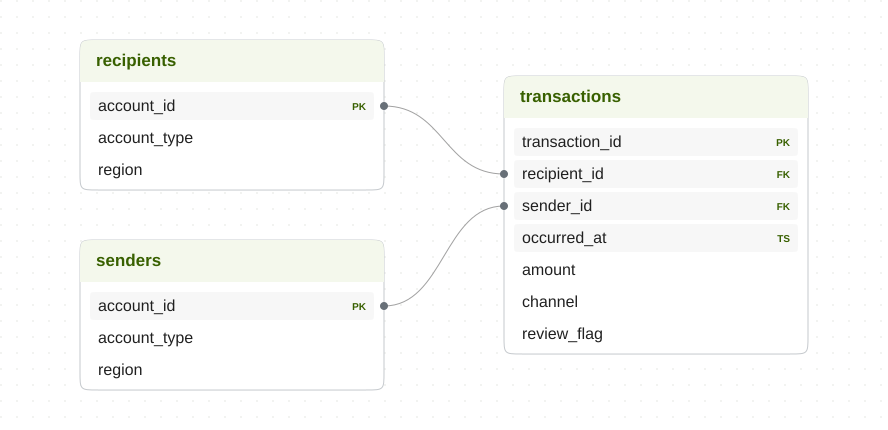

,source,foreign_key,destination
0,transactions,sender_id,senders
1,transactions,recipient_id,recipients


In [5]:
display(graph.visualize(show_cols=True))
display(pd.DataFrame([{"source": edge.src_table, "foreign_key": edge.fkey,
                       "destination": edge.dst_table} for edge in graph.edges]))


## Materialize the graph

Build a snapshot of the historical source files for training.


In [6]:
snapshot = graph.snapshot()
print("Training snapshot:", snapshot.id)


/tmp/ipykernel_1347454/3370640593.py:1: UserWarning: The kumo.engine scratch directory /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_scratch/synthetic_transaction_screening-uqrl8q6s is on Amazon EBS. Graph sampling and training-table generation read it randomly and run much slower there; local NVMe is recommended.
  snapshot = graph.snapshot()


ingest: table started phase="encode" table=senders


ingest: table producers complete phase="encode" table=senders rows=400 elapsed_ms=1


ingest: Ingestion stage progress phase=Encode table=senders shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=recipients


ingest: table producers complete phase="encode" table=recipients rows=400 elapsed_ms=1


... (16 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 3 node tables, 4 edge relations, 10800 nodes, 40000 edges


Training snapshot: 6fd0367ab0d672bcc4e7b329b283f2ba35d0ee7beb31698b80f3ee2fc8686fcd@c72b9ffa43738db2


## Define the prediction task

The comparison defines the positive class. Kumo treats the transaction’s review flag as its target, rather than an input for that transaction. For real adjudicated outcomes, model label availability explicitly before using historical flags as context.
Validate the [predictive query](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries) before generating labels.


In [7]:
QUERY = 'PREDICT transactions.review_flag = 1 FOR EACH transactions.transaction_id'
query = kumo.PredictiveQuery(graph, QUERY)
query.validate()
assert query.get_task_type() == 'binary_classification'
print(QUERY)
print("Task:", query.get_task_type())


PREDICT transactions.review_flag = 1 FOR EACH transactions.transaction_id
Task: binary_classification


## Generate training rows and inspect the splits

Use a chronological 70/15/15 split so validation and test follow training. Each transaction contributes its event-time anchor.
Export the [training table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training-tables) to inspect its actual splits: `0` is training, `1` validation, and `2` test. `ENTITY1` identifies the entity, `TIMESTAMP` its anchor, and `TARGET1` the outcome.


In [8]:
generation_plan = TrainingTableGenerationPlan(
    split="TemporalSplit([0.7, 0.15, 0.15])",
)
training_table = query.generate_training_table(snapshot, plan=generation_plan)
training_table.export(TrainingTableOutputConfig(connector=destination, table_name="training_rows/"))
training_rows = pd.read_parquet(output_dir / "training_rows")
display(training_rows.head(8))
display(training_rows.groupby("SPLIT").agg(rows=("ENTITY1", "size"),
    first_anchor=("TIMESTAMP", "min"), last_anchor=("TIMESTAMP", "max")))
assert set(training_rows.SPLIT) == {0, 1, 2}


,ENTITY1,TIMESTAMP,TARGET1,SPLIT
0,2501,2024-04-07 00:10:57,False,0
1,2502,2024-06-01 18:38:47,False,0
2,2503,2024-08-16 09:23:06,False,0
3,2504,2024-02-24 23:45:17,False,0
4,2505,2024-07-04 15:00:45,False,0
5,2507,2024-05-18 13:09:43,True,0
6,2508,2024-03-12 19:34:12,True,0
7,2509,2024-09-08 02:54:50,False,0


,rows,first_anchor,last_anchor
SPLIT,,,
0,6997,2024-01-01 02:59:09,2024-09-14 01:32:52
1,1503,2024-09-14 04:35:05,2024-11-06 04:56:32
2,1500,2024-11-06 05:29:56,2024-12-31 23:56:41


## Configure the model

Start from the supported [FAST plan](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training). Use AUPRC to select the binary model and report precision and recall alongside it.
Disable refitting to keep validation and test separate from the fitted training population.


In [9]:
plan = query.suggest_model_plan(snapshot, run_mode=RunMode.FAST)
plan.training_job.refit_trainval = False
plan.training_job.refit_full = False

plan.training_job.metrics = ["auprc", "auroc", "precision", "recall"]
plan.training_job.tune_metric = "auprc"
if SMOKE_MODE:
    plan.training_job.num_experiments = 1
    plan.optimization.max_epochs = 1
    print("Smoke mode: pipeline check only")
(output_dir / "model_plan.json").write_text(json.dumps(plan.as_json(), indent=2) + "\n")
print("Tuning metric:", plan.training_job.tune_metric)
print("Maximum epochs:", plan.optimization.max_epochs)


Tuning metric: auprc
Maximum epochs: 8


## Train and retain the model

Fit on the generated training rows and export the complete model bundle for reuse.


In [10]:
trainer = kumo.Trainer(plan, accelerator="cpu")
fit_result = trainer.fit(training_table, snapshot=snapshot,
    export_config=ModelOutputConfig(connector=destination, path="model"))
print("Saved model:", output_dir / "model")


[I 2026-11-09 18:56:06,450] A new study created in memory with name: no-name-aa88b69e-75ea-40b8-93da-c4e3401b1878


GPU available: False, used: False


TPU available: False, using: 0 TPU cores



  | Name           | Type                     | Params | Mode  | FLOPs
----------------------------------------------------------------------------
0 | target_encoder | CategoricalTargetEncoder | 0      | train | 0    
1 | metric_store   | MetricStore              | 0      | train | 0    
2 | loss           | BinaryCrossEntropyLoss   | 0      | train | 0    
3 | calibrator     | PlatScaling              | 2      | train | 0    
4 | encoder        | HeteroTensorFrameEncoder | 76.0 K | train | 0    
5 | model          | HeteroGNN                | 1.8 M  | train | 0    
6 | head           | NodePredHead             | 66.6 K | train | 0    
----------------------------------------------------------------------------
2.0 M     Trainable params
0         Non-trainable params
2.0 M     Total params
7.955     Total estimated model params size (MB)
180       Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (203 outputs left out)

Testing DataLoader 0: 100%|██████████| 2/2 [00:03<00:00,  0.62it/s]

Testing DataLoader 0: 100%|██████████| 2/2 [00:03<00:00,  0.60it/s]


────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss           0.6729642152786255
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


Saved model: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_example_runs/synthetic_transaction_screening-w5xnd_oz/output/model


## Evaluate

**Synthetic-data metrics - demonstration only.** Review the fit's metrics to check that the workflow learned from the generated patterns. AUPRC summarizes positive-class retrieval across thresholds. Precision and recall describe different costs of alerts and missed positives; the tutorial threshold is not a business-calibrated decision rule.
These are the fit's reported metrics; choose settings using validation and reserve test results for final assessment.


In [11]:
print("Synthetic-data metrics — demonstration only")
display(pd.Series(fit_result.metrics, name="value").rename_axis("metric").to_frame())
(output_dir / "metrics.json").write_text(json.dumps(fit_result.metrics, indent=2, default=float) + "\n")


Synthetic-data metrics — demonstration only


,value
metric,
val_loss,0.296372
val_auprc,0.205024
val_auroc,0.682893
val_precision,0.000000
val_recall,0.000000
test_loss,0.273864
test_auprc,0.204814
test_auroc,0.705831
test_precision,0.000000


502

## Batch predictions

Append the 40 unlabeled transactions generated earlier to the source table and materialize a new snapshot of the same graph. Their IDs were absent from training; their target column contains only nulls. Write the new rows as additional Parquet parts in the existing table directories. A new snapshot reads those parts while the training snapshot remains unchanged.


In [12]:
assert set(new_transactions.transaction_id).isdisjoint(transactions.transaction_id)
new_transactions.to_parquet(source_dir / "transactions" / "new.parquet", index=False)
scoring_population = new_transactions[["transaction_id", "occurred_at"]].rename(
    columns={"transaction_id": "ENTITY1", "occurred_at": "TIMESTAMP"})
assert not any(column.startswith("TARGET") for column in scoring_population)
assert len(scoring_population) == 40 and not scoring_population.duplicated(["ENTITY1", "TIMESTAMP"]).any()
scoring_population.to_parquet(source_dir / "scoring_population.parquet", index=False)
scoring_snapshot = graph.snapshot()
assert scoring_snapshot.id != snapshot.id
display(scoring_population.head())


ingest: table started phase="encode" table=senders


ingest: table producers complete phase="encode" table=senders rows=400 elapsed_ms=1


ingest: Ingestion stage progress phase=Encode table=senders shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=recipients


ingest: table producers complete phase="encode" table=recipients rows=400 elapsed_ms=1


ingest: Ingestion stage progress phase=Encode table=recipients shard=None progress_pct=100 current=1 total=1


... (15 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 3 node tables, 4 edge relations, 10840 nodes, 40160 edges


,ENTITY1,TIMESTAMP
0,10001,2025-01-01 11:04:39
1,10002,2025-01-01 05:23:34
2,10003,2025-01-01 18:36:46
3,10004,2025-01-01 09:39:30
4,10005,2025-01-01 10:34:52


### Prepare the scoring population

Use a [custom prediction table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/making-predictions) containing only the 40 new entity IDs and their anchor times. This keeps historical training entities out of the scoring batch.


In [13]:
prediction_table = kumo.PredictionTable.from_source_table(
    files["scoring_population"], pq=query, snapshot=scoring_snapshot, plan=generation_plan)
generated_population = pd.read_parquet(prediction_table.table_path)
assert set(generated_population.ENTITY1) == set(scoring_population.ENTITY1)
assert len(generated_population) == len(scoring_population)
display(generated_population.head())


,ENTITY1,TIMESTAMP
0,10001,2025-01-01 11:04:39
1,10002,2025-01-01 05:23:34
2,10003,2025-01-01 18:36:46
3,10004,2025-01-01 09:39:30
4,10005,2025-01-01 10:34:52


### Score the new records

Run the trained model on the new snapshot and save predictions, including anchor timestamps, as Parquet.


In [14]:
prediction_result = trainer.predict(
    prediction_table, snapshot=scoring_snapshot,
    binary_classification_threshold=DECISION_THRESHOLD,
    output_config=PredictionOutputConfig(connector=destination,
        artifact_type=PredictionArtifactType.PREDICTIONS, table_name="predictions.parquet",
        extra_fields=[MetadataField.ANCHOR_TIMESTAMP]),
)
scores = prediction_result.frame


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_scratch/synthetic_transaction_screening-uqrl8q6s/trainers/34e2680264c84645b4f801c85d5b06c0/runs/34e2680264c84645b4f801c85d5b06c0-predict-b98a6146dee1439b84835a483330d333/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_scratch/synthetic_transaction_screening-uqrl8q6s/trainers/34e2680264c84645b4f801c85d5b06c0/runs/34e2680264c84645b4f801c85d5b06c0-predict-b98a6146dee1439b84835a483330d333/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 28.53it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 24.44it/s]

### Inspect and verify the results

`ENTITY` is the new record ID and `ANCHOR_TIMESTAMP` its scoring time. Expect one output row per input. `True_PROB` is the probability of the query outcome; `TARGET_PRED` is true only when it exceeds `DECISION_THRESHOLD`. Verify IDs and times together, not row order.


In [15]:
expected = scoring_population.rename(columns={"ENTITY1": "ENTITY", "TIMESTAMP": "ANCHOR_TIMESTAMP"})
expected["ANCHOR_TIMESTAMP"] = pd.to_datetime(expected.ANCHOR_TIMESTAMP)
scores["ANCHOR_TIMESTAMP"] = pd.to_datetime(scores.ANCHOR_TIMESTAMP)

assert not scores.duplicated(["ENTITY", "ANCHOR_TIMESTAMP"]).any()
aligned = expected.merge(scores, on=["ENTITY", "ANCHOR_TIMESTAMP"], how="outer", validate="one_to_one", indicator=True)
assert aligned._merge.eq("both").all()
assert scores.True_PROB.between(0, 1).all()
assert np.isfinite(scores[["False_PROB", "True_PROB"]].to_numpy()).all()
assert np.allclose(scores.False_PROB + scores.True_PROB, 1, atol=1e-6)
assert scores.TARGET_PRED.eq(scores.True_PROB.gt(DECISION_THRESHOLD)).all()
display(scores[["ENTITY", "ANCHOR_TIMESTAMP", "True_PROB", "TARGET_PRED"]].head(10))
pd.testing.assert_frame_equal(scores, pd.read_parquet(output_dir / "predictions.parquet"))
print("Saved predictions:", output_dir / "predictions.parquet")


,ENTITY,ANCHOR_TIMESTAMP,True_PROB,TARGET_PRED
0,10001,2025-01-01 11:04:39,0.050630,False
1,10003,2025-01-01 18:36:46,0.080352,False
2,10005,2025-01-01 10:34:52,0.269035,False
3,10007,2025-01-01 01:09:55,0.174069,False
4,10009,2025-01-01 14:37:31,0.044065,False
5,10011,2025-01-01 04:10:43,0.064988,False
6,10013,2025-01-01 04:25:25,0.067458,False
7,10015,2025-01-01 02:01:05,0.068493,False
8,10017,2025-01-01 17:38:58,0.097003,False
9,10019,2025-01-01 00:41:11,0.042430,False


Saved predictions: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_example_runs/synthetic_transaction_screening-w5xnd_oz/output/predictions.parquet


## Retain and reuse

Reload the complete trusted model bundle without fitting again. Keep the source tables and compatible graph schema alongside the bundle; the model does not contain graph data.
A later process must configure scratch, rebuild the graph and snapshot, and prepare its scoring table. See [publish and retrieve models](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/publish-and-retrieve-models).


In [16]:
reloaded_trainer = kumo.Trainer.load(output_dir / "model", accelerator="cpu")
print("Reloaded model from:", output_dir / "model")
print("Retain this run directory:", run_dir)


Reloaded model from: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_example_runs/synthetic_transaction_screening-w5xnd_oz/output/model
Retain this run directory: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_transaction_screening/20261109T185600Z/kumo_example_runs/synthetic_transaction_screening-w5xnd_oz


## Cleanup

Keep the generated inputs, model, and predictions under `run_dir`. After scoring and reload checks, optionally remove only this run's scratch directory; rebuild snapshots before further prediction.


In [17]:
import shutil

if REMOVE_RUN_SCRATCH:
    shutil.rmtree(scratch_dir)
    print("Removed run scratch:", scratch_dir)
